In [ ]:
import pandas as pd

df = pd.read_csv(
    "/content/countries_analysis.csv",
    keep_default_na=False,
    na_values=[""]
)

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (100, 27)


,country,iso2,population,population_growth_percent,land_area_sq_km,population_density_per_sq_km,gdp_ppp_usd_billions,gdp_per_capita_usd,median_age_years,life_expectancy_years,...,exports_usd_billions,imports_usd_billions,unemployment_percent,inflation_percent,coastline_km,land_boundaries_km,electricity_consumption_billion_kwh,electricity_imports_billion_kwh,energy_consumption_per_capita_million_btu,military_expenditure_percent_gdp
0,Afghanistan,AF,49474805,2.9,652230,75.9,82.2,2000,18.4,54.4,...,1.5,7.0,13.3,-6.6,NaN,5987.0,6.5,6.2,3.38,3.3
1,Albania,AL,2551837,-1.1,27398,93.1,51.4,18900,37.9,79.9,...,9.8,11.7,10.3,2.2,362.0,691.0,7.5,1.9,27.41,2.0
2,Algeria,DZ,47735685,1.5,2381740,20.0,722.9,15400,29.3,77.9,...,59.4,51.1,11.5,4.0,998.0,6734.0,85.7,0.5,61.84,8.0
3,Angola,AO,38984796,3.3,1246700,31.3,278.2,7300,16.6,62.9,...,36.9,22.7,14.5,28.2,1600.0,5369.0,16.2,NaN,9.15,1.0
4,Argentina,AR,45418098,0.3,2736690,16.6,1213.0,26500,34.6,78.8,...,96.9,80.0,7.9,73.1,4989.0,11968.0,114.7,11.4,78.50,0.6


,country,population
58,Mexico,130739927
74,Russia,140134279
8,Bangladesh,174370536
14,Brazil,221359387
67,Nigeria,244344065
68,Pakistan,257047044
43,Indonesia,283587097
93,United States,338016259
23,China,1407181209
42,India,1419316933


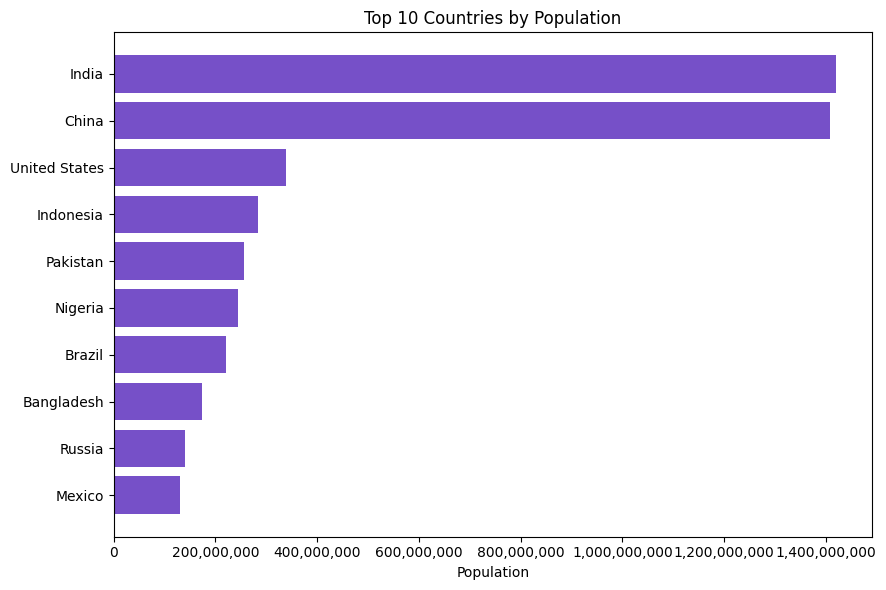

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

df["population"] = pd.to_numeric(df["population"], errors="coerce")
top_population = df.nlargest(10, "population").sort_values("population")

display(top_population[["country", "population"]])

plt.figure(figsize=(9, 6))
plt.barh(top_population["country"], top_population["population"], color="#7650c8")
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.title("Top 10 Countries by Population")
plt.xlabel("Population")
plt.tight_layout()
plt.show()

,country,gdp_per_capita_usd
46,Italy,53100
34,France,54500
20,Canada,56700
7,Bahrain,59100
76,Saudi Arabia,62700
37,Germany,62800
10,Belgium,63100
91,United Arab Emirates,68600
65,Netherlands,70900
93,United States,75500


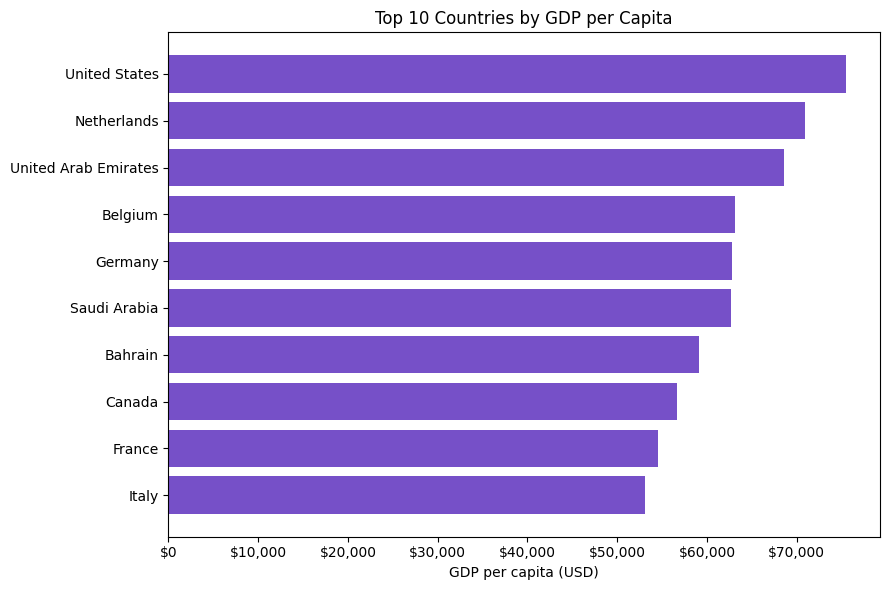

In [ ]:
df["gdp_per_capita_usd"] = pd.to_numeric(
    df["gdp_per_capita_usd"], errors="coerce"
)
top_gdp = df.nlargest(10, "gdp_per_capita_usd").sort_values(
    "gdp_per_capita_usd"
)

display(top_gdp[["country", "gdp_per_capita_usd"]])

plt.figure(figsize=(9, 6))
plt.barh(top_gdp["country"], top_gdp["gdp_per_capita_usd"], color="#7650c8")
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x:,.0f}"))
plt.title("Top 10 Countries by GDP per Capita")
plt.xlabel("GDP per capita (USD)")
plt.tight_layout()
plt.show()

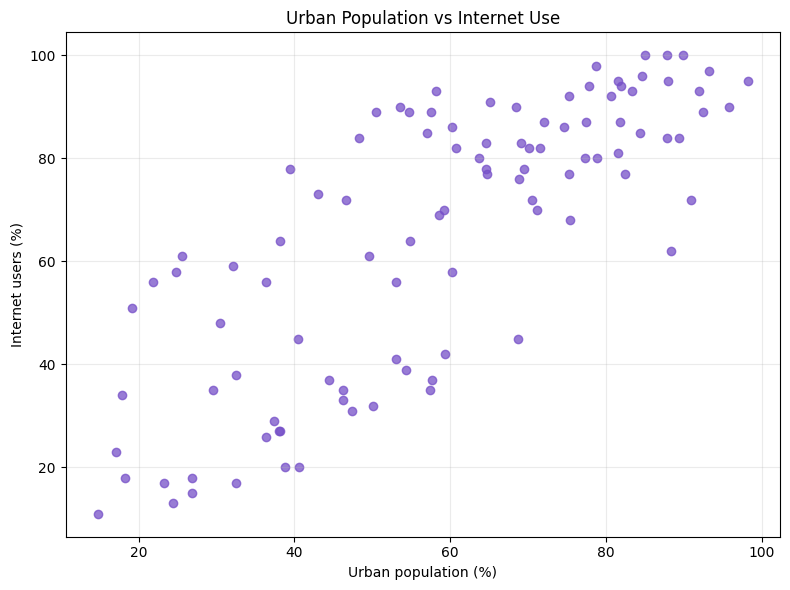

Countries included: 100
Correlation: 0.78


In [ ]:
x_col = "urban_population_percent"
y_col = "internet_users_percent"

plot_data = df[[x_col, y_col]].apply(pd.to_numeric, errors="coerce").dropna()
correlation = plot_data[x_col].corr(plot_data[y_col])

plt.figure(figsize=(8, 6))
plt.scatter(plot_data[x_col], plot_data[y_col], color="#7650c8", alpha=0.75)
plt.title("Urban Population vs Internet Use")
plt.xlabel("Urban population (%)")
plt.ylabel("Internet users (%)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Countries included: {len(plot_data)}")
print(f"Correlation: {correlation:.2f}")

,country,population,gdp_per_capita_usd
25,"Congo, Democratic Republic of the",119038825,1500
33,Ethiopia,121372632,2900
84,Tanzania,69145464,3700
16,Burma (Myanmar),57931718,5300
68,Pakistan,257047044,5500
67,Nigeria,244344065,5700
8,Bangladesh,174370536,8500
42,India,1419316933,9800
71,Philippines,118277063,10400
79,South Africa,61089926,13600


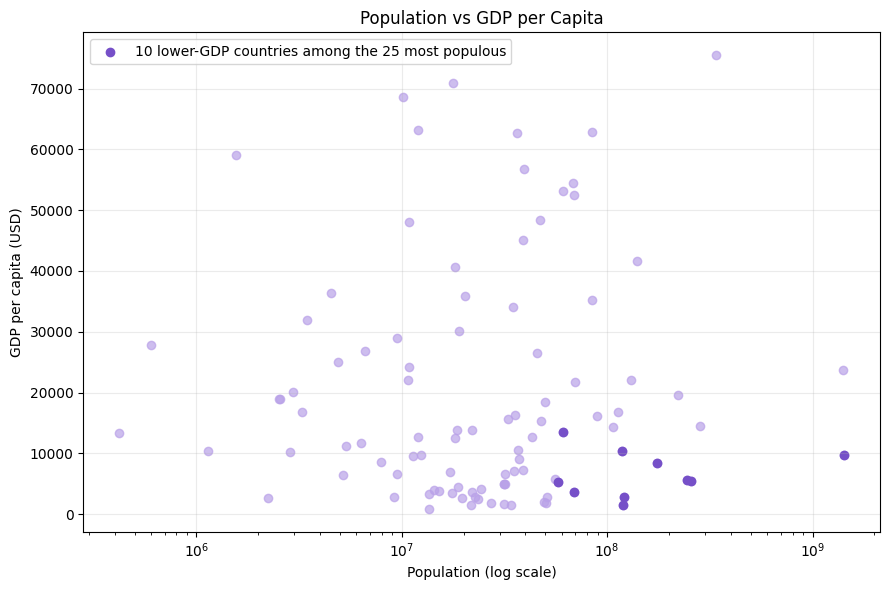

In [ ]:
df["population"] = pd.to_numeric(df["population"], errors="coerce")
df["gdp_per_capita_usd"] = pd.to_numeric(
    df["gdp_per_capita_usd"], errors="coerce"
)

valid = df.dropna(subset=["population", "gdp_per_capita_usd"])
top25_population = valid.nlargest(25, "population")
lower_gdp = top25_population.nsmallest(10, "gdp_per_capita_usd")

display(lower_gdp[["country", "population", "gdp_per_capita_usd"]])

plt.figure(figsize=(9, 6))
plt.scatter(
    valid["population"],
    valid["gdp_per_capita_usd"],
    color="#b9a1e8",
    alpha=0.7
)
plt.scatter(
    lower_gdp["population"],
    lower_gdp["gdp_per_capita_usd"],
    color="#7650c8",
    label="10 lower-GDP countries among the 25 most populous"
)
plt.xscale("log")
plt.xlabel("Population (log scale)")
plt.ylabel("GDP per capita (USD)")
plt.title("Population vs GDP per Capita")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


Countries included: 100
Correlation: 0.78


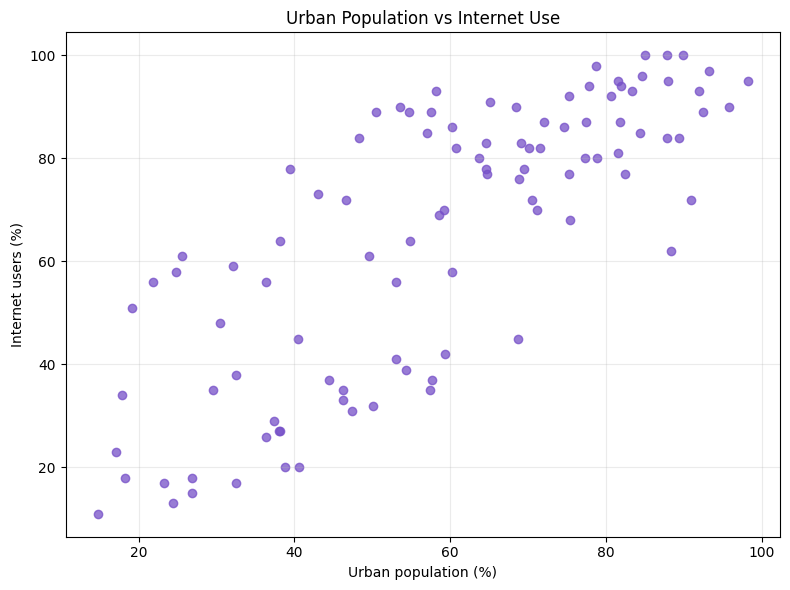

In [ ]:
x_col = "urban_population_percent"
y_col = "internet_users_percent"

plot_data = df[[x_col, y_col]].apply(pd.to_numeric, errors="coerce").dropna()
correlation = plot_data[x_col].corr(plot_data[y_col])

print("Countries included:", len(plot_data))
print("Correlation:", round(correlation, 2))

plt.figure(figsize=(8, 6))
plt.scatter(plot_data[x_col], plot_data[y_col], color="#7650c8", alpha=0.75)
plt.title("Urban Population vs Internet Use")
plt.xlabel("Urban population (%)")
plt.ylabel("Internet users (%)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

,country,median_age_years
66,Niger,15.3
89,Uganda,16.4
56,Mali,16.5
3,Angola,16.6
21,Chad,16.9
25,"Congo, Democratic Republic of the",16.9
12,Benin,17.2
62,Mozambique,17.4
17,Burundi,17.6
0,Afghanistan,18.4


,country,median_age_years
46,Italy,48.8
80,Spain,47.2
37,Germany,46.9
73,Romania,45.8
90,Ukraine,44.6
27,Czechia,44.4
78,Serbia,44.1
72,Poland,43.4
20,Canada,42.8
34,France,42.7


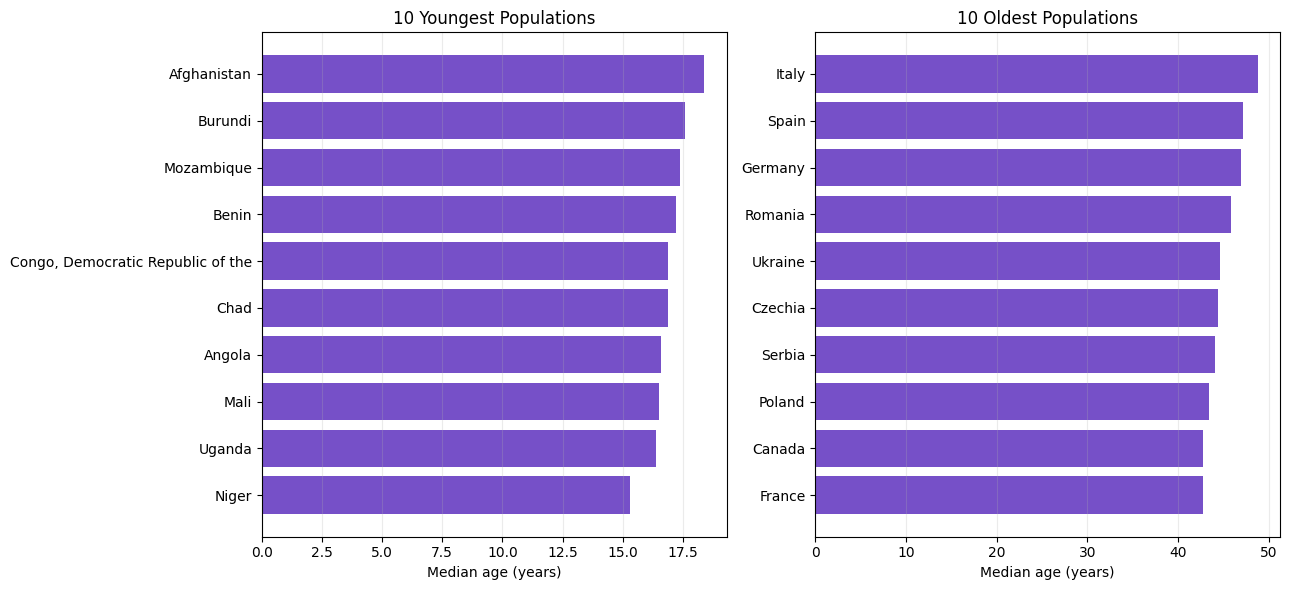

In [ ]:
df["median_age_years"] = pd.to_numeric(
    df["median_age_years"], errors="coerce"
)
age_data = df.dropna(subset=["median_age_years"])

youngest = age_data.nsmallest(10, "median_age_years")
oldest = age_data.nlargest(10, "median_age_years")

display(youngest[["country", "median_age_years"]])
display(oldest[["country", "median_age_years"]])

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, data, title in [
    (axes[0], youngest.sort_values("median_age_years"), "10 Youngest Populations"),
    (axes[1], oldest.sort_values("median_age_years"), "10 Oldest Populations"),
]:
    ax.barh(data["country"], data["median_age_years"], color="#7650c8")
    ax.set_title(title)
    ax.set_xlabel("Median age (years)")
    ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()


,country,population,internet_users_percent
33,Ethiopia,121372632,17.0
68,Pakistan,257047044,27.0
84,Tanzania,69145464,29.0
25,"Congo, Democratic Republic of the",119038825,31.0
67,Nigeria,244344065,39.0
8,Bangladesh,174370536,45.0
42,India,1419316933,56.0
16,Burma (Myanmar),57931718,59.0
43,Indonesia,283587097,69.0
30,Egypt,112870457,73.0


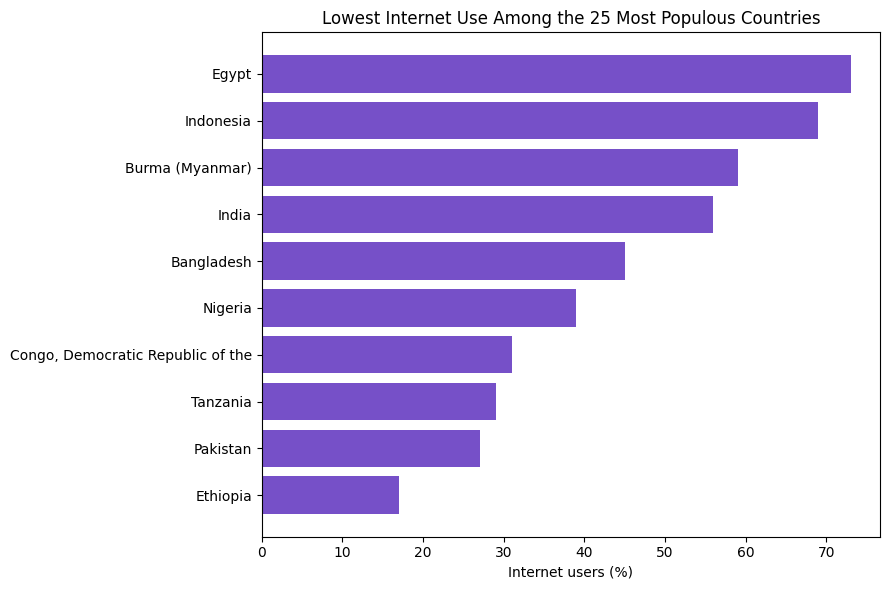

In [ ]:
df["internet_users_percent"] = pd.to_numeric(
    df["internet_users_percent"], errors="coerce"
)

valid = df.dropna(subset=["population", "internet_users_percent"])
top25_population = valid.nlargest(25, "population")
low_internet = top25_population.nsmallest(10, "internet_users_percent")

display(low_internet[[
    "country", "population", "internet_users_percent"
]])

chart_data = low_internet.sort_values("internet_users_percent")
plt.figure(figsize=(9, 6))
plt.barh(
    chart_data["country"],
    chart_data["internet_users_percent"],
    color="#7650c8"
)
plt.xlabel("Internet users (%)")
plt.title("Lowest Internet Use Among the 25 Most Populous Countries")
plt.tight_layout()
plt.show()

,country,military_expenditure_percent_gdp
56,Mali,4.3
15,Burkina Faso,4.5
72,Poland,4.5
47,Jordan,4.5
6,Azerbaijan,5.1
5,Armenia,5.5
83,Syria,6.5
74,Russia,7.0
76,Saudi Arabia,7.1
2,Algeria,8.0


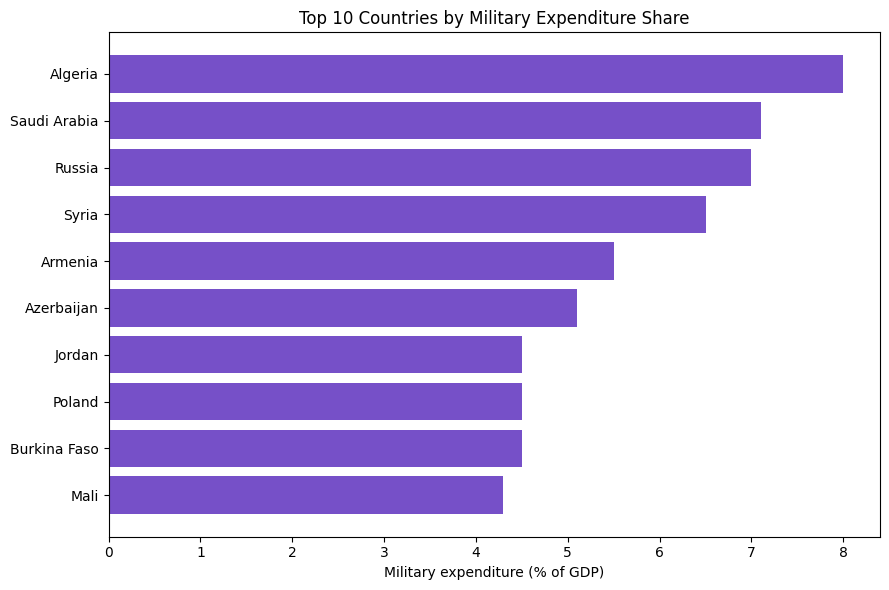

In [ ]:
df["military_expenditure_percent_gdp"] = pd.to_numeric(
    df["military_expenditure_percent_gdp"], errors="coerce"
)

top_military = (
    df.dropna(subset=["military_expenditure_percent_gdp"])
      .nlargest(10, "military_expenditure_percent_gdp")
      .sort_values("military_expenditure_percent_gdp")
)

display(top_military[["country", "military_expenditure_percent_gdp"]])

plt.figure(figsize=(9, 6))
plt.barh(
    top_military["country"],
    top_military["military_expenditure_percent_gdp"],
    color="#7650c8"
)
plt.xlabel("Military expenditure (% of GDP)")
plt.title("Top 10 Countries by Military Expenditure Share")
plt.tight_layout()
plt.show()

,country,electricity_import_share_percent
60,Montenegro,200.000000
0,Afghanistan,95.384615
66,Niger,75.000000
63,Namibia,74.358974
32,Eswatini,69.230769
62,Mozambique,63.846154
52,Lesotho,62.500000
86,Togo,61.111111
12,Benin,53.333333
15,Burkina Faso,51.612903


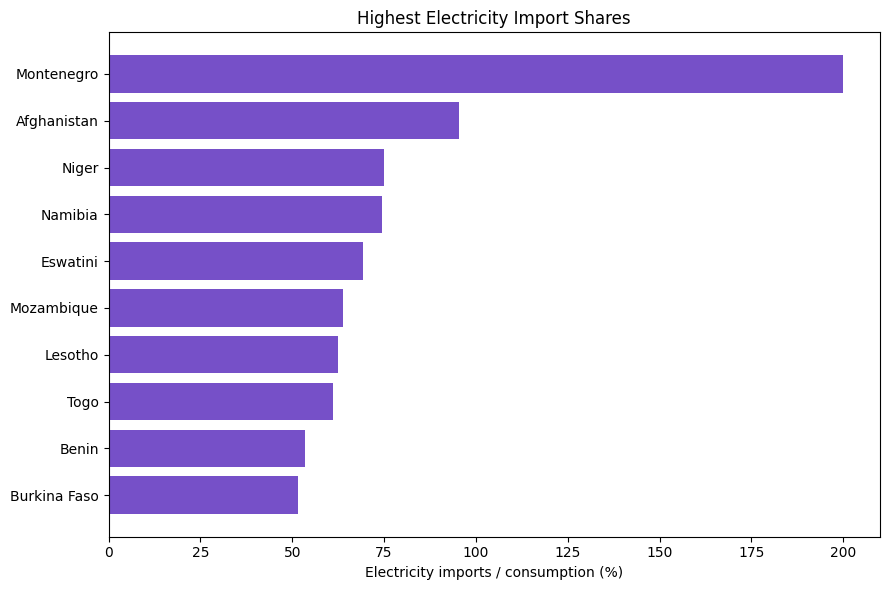

In [ ]:
df["electricity_consumption_billion_kwh"] = pd.to_numeric(
    df["electricity_consumption_billion_kwh"], errors="coerce"
)
df["electricity_imports_billion_kwh"] = pd.to_numeric(
    df["electricity_imports_billion_kwh"], errors="coerce"
)

energy = df.dropna(subset=[
    "electricity_consumption_billion_kwh",
    "electricity_imports_billion_kwh"
]).copy()

energy = energy[energy["electricity_consumption_billion_kwh"] > 0]
energy["electricity_import_share_percent"] = (
    energy["electricity_imports_billion_kwh"]
    / energy["electricity_consumption_billion_kwh"] * 100
)

top_import_share = energy.nlargest(10, "electricity_import_share_percent")
display(top_import_share[[
    "country", "electricity_import_share_percent"
]])

chart_data = top_import_share.sort_values("electricity_import_share_percent")
plt.figure(figsize=(9, 6))
plt.barh(
    chart_data["country"],
    chart_data["electricity_import_share_percent"],
    color="#7650c8"
)
plt.xlabel("Electricity imports / consumption (%)")
plt.title("Highest Electricity Import Shares")
plt.tight_layout()
plt.show()

,country,coastline_km,land_area_sq_km
20,Canada,202080.0,9093507
43,Indonesia,54716.0,1811569
74,Russia,37653.0,16377742
71,Philippines,36289.0,298170
93,United States,19924.0,9147593
23,China,14500.0,9326410
92,United Kingdom,12429.0,241930
58,Mexico,9330.0,1943945
46,Italy,7600.0,294140
14,Brazil,7491.0,8358140


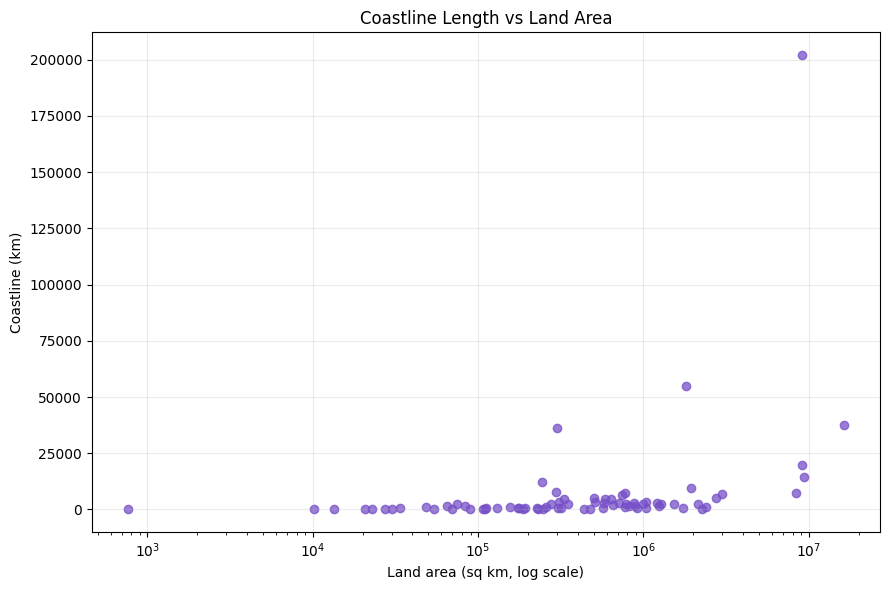

In [ ]:
df["coastline_km"] = pd.to_numeric(df["coastline_km"], errors="coerce")
df["land_area_sq_km"] = pd.to_numeric(df["land_area_sq_km"], errors="coerce")

coastal = df.dropna(subset=["coastline_km", "land_area_sq_km"])
coastal = coastal[coastal["land_area_sq_km"] > 0]

display(
    coastal.nlargest(10, "coastline_km")[["country", "coastline_km", "land_area_sq_km"]]
)

plt.figure(figsize=(9, 6))
plt.scatter(
    coastal["land_area_sq_km"],
    coastal["coastline_km"],
    color="#7650c8",
    alpha=0.75
)
plt.xscale("log")
plt.xlabel("Land area (sq km, log scale)")
plt.ylabel("Coastline (km)")
plt.title("Coastline Length vs Land Area")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Key findings

- Population: India and China are the two most populous countries in this dataset, at about 1.42 billion and 1.41 billion people.


- GDP per capita: The United States ranks highest in this dataset, followed by the Netherlands and the United Arab Emirates.

- Development gap: Among the 25 most populous countries, the Democratic Republic of the Congo and Ethiopia have the lowest GDP per capita in this dataset.

- Digital access: Urban population and internet use have a strong positive correlation (0.78) among the countries with data for both indicators.

Countries included: 100
Spearman correlation: 0.91


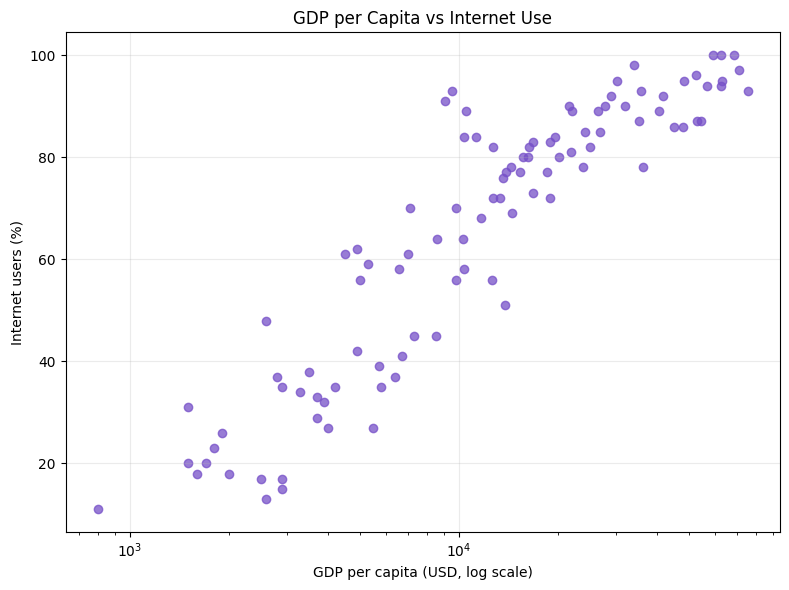

In [ ]:
economic = df[["gdp_per_capita_usd", "internet_users_percent"]].apply(
    pd.to_numeric, errors="coerce"
).dropna()

economic = economic[economic["gdp_per_capita_usd"] > 0]
correlation = economic["gdp_per_capita_usd"].corr(
    economic["internet_users_percent"],
    method="spearman"
)

print("Countries included:", len(economic))
print("Spearman correlation:", round(correlation, 2))

plt.figure(figsize=(8, 6))
plt.scatter(
    economic["gdp_per_capita_usd"],
    economic["internet_users_percent"],
    color="#7650c8",
    alpha=0.75
)
plt.xscale("log")
plt.xlabel("GDP per capita (USD, log scale)")
plt.ylabel("Internet users (%)")
plt.title("GDP per Capita vs Internet Use")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

- Digital readiness: GDP per capita and internet use have a strong positive association (Spearman correlation: 0.91) among the countries with data for both indicators.

Countries included: 86
Spearman correlation: 0.81


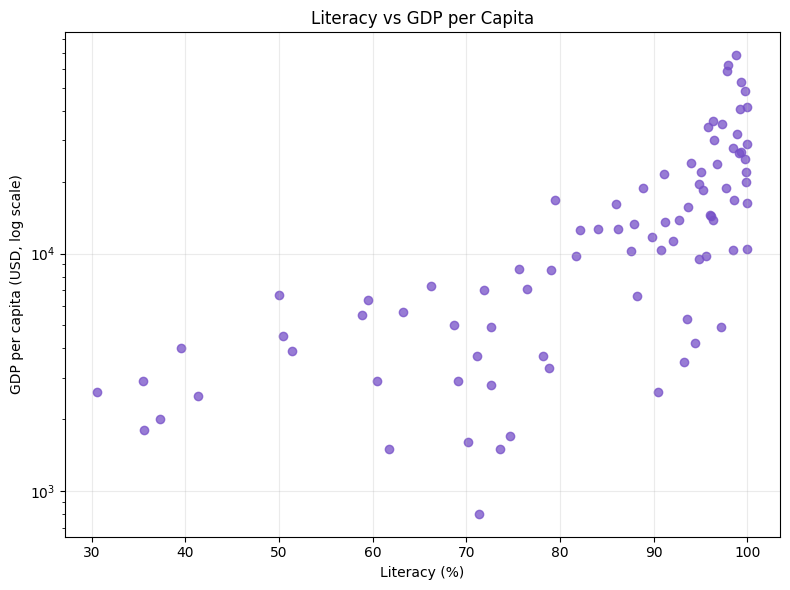

In [ ]:
literacy_economy = df[["literacy_percent", "gdp_per_capita_usd"]].apply(
    pd.to_numeric, errors="coerce"
).dropna()

literacy_economy = literacy_economy[literacy_economy["gdp_per_capita_usd"] > 0]
correlation = literacy_economy["literacy_percent"].corr(
    literacy_economy["gdp_per_capita_usd"],
    method="spearman"
)

print("Countries included:", len(literacy_economy))
print("Spearman correlation:", round(correlation, 2))

plt.figure(figsize=(8, 6))
plt.scatter(
    literacy_economy["literacy_percent"],
    literacy_economy["gdp_per_capita_usd"],
    color="#7650c8",
    alpha=0.75
)
plt.yscale("log")
plt.xlabel("Literacy (%)")
plt.ylabel("GDP per capita (USD, log scale)")
plt.title("Literacy vs GDP per Capita")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

- Literacy and prosperity: Literacy and GDP per capita have a strong positive association (Spearman correlation: 0.81) among countries with both values recorded.

In [ ]:
!pip -q install country_converter

import country_converter as coco

converter = coco.CountryConverter()
df["region"] = converter.convert(
    names=df["iso2"].astype(str).str.upper().tolist(),
    src="ISO2",
    to="UNregion",
    not_found=None
)

display(df[["country", "iso2", "region"]].head(15))
print("Countries without a mapped region:", df["region"].isna().sum())

,country,iso2,region
0,Afghanistan,AF,Southern Asia
1,Albania,AL,Southern Europe
2,Algeria,DZ,Northern Africa
3,Angola,AO,Middle Africa
4,Argentina,AR,South America
5,Armenia,AM,Western Asia
6,Azerbaijan,AZ,Western Asia
7,Bahrain,BH,Western Asia
8,Bangladesh,BD,Southern Asia
9,Belarus,BY,Eastern Europe


Countries without a mapped region: 0


In [ ]:
from google.colab import files

df.to_csv("countries_analysis_with_region.csv", index=False)
files.download("countries_analysis_with_region.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
check = pd.read_csv(
    "countries_analysis_with_region.csv",
    keep_default_na=False,
    na_values=[""]
)
print(check.columns.tolist())
display(check[["country", "iso2", "region"]].head(10))

['country', 'iso2', 'population', 'population_growth_percent', 'land_area_sq_km', 'population_density_per_sq_km', 'gdp_ppp_usd_billions', 'gdp_per_capita_usd', 'median_age_years', 'life_expectancy_years', 'birth_rate_per_1000', 'death_rate_per_1000', 'infant_mortality_per_1000', 'urban_population_percent', 'urbanization_rate_percent', 'literacy_percent', 'internet_users_percent', 'exports_usd_billions', 'imports_usd_billions', 'unemployment_percent', 'inflation_percent', 'coastline_km', 'land_boundaries_km', 'electricity_consumption_billion_kwh', 'electricity_imports_billion_kwh', 'energy_consumption_per_capita_million_btu', 'military_expenditure_percent_gdp', 'region']


,country,iso2,region
0,Afghanistan,AF,Southern Asia
1,Albania,AL,Southern Europe
2,Algeria,DZ,Northern Africa
3,Angola,AO,Middle Africa
4,Argentina,AR,South America
5,Armenia,AM,Western Asia
6,Azerbaijan,AZ,Western Asia
7,Bahrain,BH,Western Asia
8,Bangladesh,BD,Southern Asia
9,Belarus,BY,Eastern Europe


In [ ]:
from google.colab import files

df.to_csv("countries_analysis_with_region.csv", index=False)
print(df[["country", "iso2", "region"]].head(10).to_string(index=False))
files.download("countries_analysis_with_region.csv")

    country iso2          region
Afghanistan   AF   Southern Asia
    Albania   AL Southern Europe
    Algeria   DZ Northern Africa
     Angola   AO   Middle Africa
  Argentina   AR   South America
    Armenia   AM    Western Asia
 Azerbaijan   AZ    Western Asia
    Bahrain   BH    Western Asia
 Bangladesh   BD   Southern Asia
    Belarus   BY  Eastern Europe


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
from google.colab import files

columns = df.columns.tolist()
columns.remove("region")
columns.insert(columns.index("iso2") + 1, "region")
df = df[columns]

df.to_csv("countries_analysis_with_region.csv", index=False)
display(df[["country", "iso2", "region"]].head(10))
files.download("countries_analysis_with_region.csv")

NameError: name 'df' is not defined

In [2]:
from google.colab import files
import io
import pandas as pd

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(
    io.BytesIO(uploaded[filename]),
    keep_default_na=False,
    na_values=[""]
)

!pip -q install country_converter

import country_converter as coco

converter = coco.CountryConverter()
df["region"] = converter.convert(
    names=df["iso2"].astype(str).str.upper().tolist(),
    src="ISO2",
    to="UNregion",
    not_found=None
)

columns = df.columns.tolist()
columns.remove("region")
columns.insert(columns.index("iso2") + 1, "region")
df = df[columns]

print("Countries without a mapped region:", df["region"].isna().sum())
display(df[["country", "iso2", "region"]].head(10))

output_file = "countries_analysis_with_region.csv"
df.to_csv(output_file, index=False)
files.download(output_file)

Saving countries_analysis.csv to countries_analysis.csv
Countries without a mapped region: 0


,country,iso2,region
0,Afghanistan,AF,Southern Asia
1,Albania,AL,Southern Europe
2,Algeria,DZ,Northern Africa
3,Angola,AO,Middle Africa
4,Argentina,AR,South America
5,Armenia,AM,Western Asia
6,Azerbaijan,AZ,Western Asia
7,Bahrain,BH,Western Asia
8,Bangladesh,BD,Southern Asia
9,Belarus,BY,Eastern Europe


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>